In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
os.makedirs(os.path.expanduser('~/.kaggle'), exist_ok=True)
os.system('cp /content/drive/MyDrive/kaggle.json ~/.kaggle/')
os.system('chmod 600 ~/.kaggle/kaggle.json')

!pip install -q kaggle
!kaggle datasets download -d briscdataset/brisc2025
!unzip -q brisc2025.zip -d ./brisc_data

Mounted at /content/drive
Dataset URL: https://www.kaggle.com/datasets/briscdataset/brisc2025
License(s): Attribution 4.0 International (CC BY 4.0)
100% 250M/250M [00:01<00:00, 192MB/s]



In [ ]:
import os, cv2, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import backend as K
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.applications import EfficientNetB3
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
IMG_SIZE = 256
BATCH_SIZE = 16

In [ ]:
os.listdir('./brisc_data/brisc2025')

['segmentation_task',
 'classification_task',
 'manifest.json',
 'manifest.json.sha256',
 'README.md',
 'manifest.csv.sha256',
 'manifest.csv']

In [ ]:
print(os.listdir('./brisc_data/brisc2025/classification_task'))
print(os.listdir('./brisc_data/brisc2025/segmentation_task'))

['test', 'train']
['test', 'train']


In [ ]:
print(os.listdir('./brisc_data/brisc2025/classification_task/train'))
print(os.listdir('./brisc_data/brisc2025/segmentation_task/train'))

['meningioma', 'pituitary', 'no_tumor', 'glioma']
['images', 'masks']


In [ ]:
BASE = './brisc_data/brisc2025'

# ── Classification ──────────────────────────────────────────
clf_data = []
for split in ['train', 'test']:
    for label in ['glioma', 'meningioma', 'pituitary', 'no_tumor']:
        folder = f"{BASE}/classification_task/{split}/{label}"
        for fname in os.listdir(folder):
            clf_data.append({'filepath': f"{folder}/{fname}", 'label': label, 'split': split})

clf_df = pd.DataFrame(clf_data)
print(clf_df['label'].value_counts())

# ── Segmentation ────────────────────────────────────────────
seg_data = []
img_dir  = f"{BASE}/segmentation_task/train/images"
mask_dir = f"{BASE}/segmentation_task/train/masks"
for fname in os.listdir(img_dir):
    mask_path = f"{mask_dir}/{fname}"
    if os.path.exists(mask_path):
        seg_data.append({'filepath': f"{img_dir}/{fname}", 'mask_path': mask_path})

seg_df = pd.DataFrame(seg_data)
print(f"Seg samples: {len(seg_df)}")

label
pituitary     1757
meningioma    1635
glioma        1401
no_tumor      1207
Name: count, dtype: int64
Seg samples: 0


In [ ]:
imgs  = os.listdir(f"{BASE}/segmentation_task/train/images")
masks = os.listdir(f"{BASE}/segmentation_task/train/masks")
print("Images:", imgs[:3])
print("Masks:", masks[:3])

Images: ['brisc2025_train_01468_me_ax_t1.jpg', 'brisc2025_train_01027_gl_sa_t1.jpg', 'brisc2025_train_02425_me_sa_t1.jpg']
Masks: ['brisc2025_train_01728_me_co_t1.png', 'brisc2025_train_02267_me_sa_t1.png', 'brisc2025_train_00166_gl_ax_t1.png']


In [ ]:
seg_data = []
img_dir  = f"{BASE}/segmentation_task/train/images"
mask_dir = f"{BASE}/segmentation_task/train/masks"

for fname in os.listdir(img_dir):
    base_name = fname.replace('.jpg', '')
    mask_path = f"{mask_dir}/{base_name}.png"
    if os.path.exists(mask_path):
        seg_data.append({'filepath': f"{img_dir}/{fname}", 'mask_path': mask_path})

seg_df = pd.DataFrame(seg_data)
print(f"Seg samples: {len(seg_df)}")

Seg samples: 3933


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_df = clf_df[clf_df['split'] == 'train'].reset_index(drop=True)
test_df  = clf_df[clf_df['split'] == 'test'].reset_index(drop=True)

datagen = ImageDataGenerator(rescale=1./255., validation_split=0.1,
    rotation_range=15, zoom_range=0.1,
    horizontal_flip=True, brightness_range=[0.8,1.2])

train_gen = datagen.flow_from_dataframe(train_df, x_col='filepath', y_col='label',
    subset='training', class_mode='categorical',
    batch_size=BATCH_SIZE, target_size=(IMG_SIZE, IMG_SIZE))

val_gen = datagen.flow_from_dataframe(train_df, x_col='filepath', y_col='label',
    subset='validation', class_mode='categorical',
    batch_size=BATCH_SIZE, target_size=(IMG_SIZE, IMG_SIZE))

test_gen = ImageDataGenerator(rescale=1./255.).flow_from_dataframe(
    test_df, x_col='filepath', y_col='label',
    class_mode='categorical', batch_size=BATCH_SIZE,
    shuffle=False, target_size=(IMG_SIZE, IMG_SIZE))

# EfficientNetB3
base = EfficientNetB3(weights='imagenet', include_top=False, input_shape=(IMG_SIZE,IMG_SIZE,3))
for layer in base.layers[:-30]: layer.trainable = False
for layer in base.layers[-30:]: layer.trainable = True

x = base.output
x = GlobalAveragePooling2D()(x)
x = BatchNormalization()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.4)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
out = Dense(4, activation='softmax')(x)

clf_model = Model(base.input, out)
clf_model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
                  loss='categorical_crossentropy', metrics=['accuracy'])

clf_model.fit(train_gen,
    steps_per_epoch=train_gen.n // BATCH_SIZE,
    epochs=50, validation_data=val_gen,
    validation_steps=val_gen.n // BATCH_SIZE,
    callbacks=[
        ModelCheckpoint('efficientnet_clf.keras', save_best_only=True, verbose=1),
        EarlyStopping(monitor='val_loss', patience=10, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', patience=5, factor=0.2, verbose=1)
    ])

_, acc = clf_model.evaluate(test_gen)
print(f"\n✅ Accuracy: {acc*100:.2f}%")
preds = np.argmax(clf_model.predict(test_gen), axis=1)
print(classification_report(test_gen.classes, preds,
      target_names=list(train_gen.class_indices.keys())))

clf_model.save('/content/drive/MyDrive/efficientnet_clf_brisc.keras')

Found 4500 validated image filenames belonging to 4 classes.
Found 500 validated image filenames belonging to 4 classes.
Found 1000 validated image filenames belonging to 4 classes.
43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/50
281/281 ━━━━━━━━━━━━━━━━━━━━ 0s 429ms/step - accuracy: 0.3053 - loss: 1.7685
Epoch 1: val_loss improved from None to 1.77976, saving model to efficientnet_clf.keras

Epoch 1: finished saving model to efficientnet_clf.keras
281/281 ━━━━━━━━━━━━━━━━━━━━ 202s 513ms/step - accuracy: 0.3336 - loss: 1.6203 - val_accuracy: 0.0060 - val_loss: 1.7798 - learning_rate: 1.0000e-04
Epoch 2/50
  1/281 ━━━━━━━━━━━━━━━━━━━━ 20s 73ms/step - accuracy: 0.3750 - loss: 1.6219

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 2: val_loss did not improve from 1.77976
281/281 ━━━━━━━━━━━━━━━━━━━━ 10s 35ms/step - accuracy: 0.3750 - loss: 1.6219 - val_accuracy: 0.0000e+00 - val_loss: 1.8073 - learning_rate: 1.0000e-04
Epoch 3/50
281/281 ━━━━━━━━━━━━━━━━━━━━ 0s 304ms/step - accuracy: 0.3874 - loss: 1.4055
Epoch 3: val_loss improved from 1.77976 to 1.63682, saving model to efficientnet_clf.keras

Epoch 3: finished saving model to efficientnet_clf.keras
281/281 ━━━━━━━━━━━━━━━━━━━━ 96s 343ms/step - accuracy: 0.3865 - loss: 1.3946 - val_accuracy: 0.0020 - val_loss: 1.6368 - learning_rate: 1.0000e-04
Epoch 4/50
  1/281 ━━━━━━━━━━━━━━━━━━━━ 20s 72ms/step - accuracy: 0.4375 - loss: 1.1857
Epoch 4: val_loss did not improve from 1.63682
281/281 ━━━━━━━━━━━━━━━━━━━━ 8s 29ms/step - accuracy: 0.4375 - loss: 1.1857 - val_accuracy: 0.0000e+00 - val_loss: 1.6507 - learning_rate: 1.0000e-04
Epoch 5/50
281/281 ━━━━━━━━━━━━━━━━━━━━ 0s 306ms/step - accuracy: 0.4038 - loss: 1.3467
Epoch 5: val_loss did not improve from 1.63

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
# Unfreeze more layers
for layer in base.layers:
    layer.trainable = True

clf_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),  # lower LR
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

clf_model.fit(train_gen,
    steps_per_epoch=train_gen.n // BATCH_SIZE,
    epochs=30, validation_data=val_gen,
    validation_steps=val_gen.n // BATCH_SIZE,
    callbacks=[
        ModelCheckpoint('efficientnet_clf_v2.keras', save_best_only=True, verbose=1),
        EarlyStopping(monitor='val_loss', patience=8, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', patience=4, factor=0.5, verbose=1)
    ])

Epoch 1/30
281/281 ━━━━━━━━━━━━━━━━━━━━ 0s 566ms/step - accuracy: 0.4558 - loss: 1.2855
Epoch 1: val_loss improved from None to 2.43487, saving model to efficientnet_clf_v2.keras

Epoch 1: finished saving model to efficientnet_clf_v2.keras
281/281 ━━━━━━━━━━━━━━━━━━━━ 305s 652ms/step - accuracy: 0.5457 - loss: 1.0969 - val_accuracy: 0.0000e+00 - val_loss: 2.4349 - learning_rate: 1.0000e-05
Epoch 2/30
  1/281 ━━━━━━━━━━━━━━━━━━━━ 1:04 230ms/step - accuracy: 0.8125 - loss: 0.7561

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 2: val_loss improved from 2.43487 to 2.43344, saving model to efficientnet_clf_v2.keras

Epoch 2: finished saving model to efficientnet_clf_v2.keras
281/281 ━━━━━━━━━━━━━━━━━━━━ 12s 41ms/step - accuracy: 0.8125 - loss: 0.7561 - val_accuracy: 0.0000e+00 - val_loss: 2.4334 - learning_rate: 1.0000e-05
Epoch 3/30
281/281 ━━━━━━━━━━━━━━━━━━━━ 0s 349ms/step - accuracy: 0.6974 - loss: 0.7523
Epoch 3: val_loss improved from 2.43344 to 1.36811, saving model to efficientnet_clf_v2.keras

Epoch 3: finished saving model to efficientnet_clf_v2.keras
281/281 ━━━━━━━━━━━━━━━━━━━━ 109s 388ms/step - accuracy: 0.7148 - loss: 0.7097 - val_accuracy: 0.0000e+00 - val_loss: 1.3681 - learning_rate: 1.0000e-05
Epoch 4/30
  1/281 ━━━━━━━━━━━━━━━━━━━━ 59s 211ms/step - accuracy: 0.7500 - loss: 0.5172
Epoch 4: val_loss improved from 1.36811 to 1.36216, saving model to efficientnet_clf_v2.keras

Epoch 4: finished saving model to efficientnet_clf_v2.keras
281/281 ━━━━━━━━━━━━━━━━━━━━ 10s 36ms/step - accuracy

In [ ]:
_, acc = clf_model.evaluate(test_gen)
print(f"Accuracy: {acc*100:.2f}%")

preds = np.argmax(clf_model.predict(test_gen), axis=1)
print(classification_report(test_gen.classes, preds,
      target_names=list(train_gen.class_indices.keys())))

63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 182ms/step - accuracy: 0.9140 - loss: 0.2217
Accuracy: 91.40%
63/63 ━━━━━━━━━━━━━━━━━━━━ 25s 230ms/step
              precision    recall  f1-score   support

      glioma       0.85      0.94      0.90       254
  meningioma       0.93      0.79      0.86       306
    no_tumor       0.93      0.99      0.96       140
   pituitary       0.95      0.98      0.96       300

    accuracy                           0.91      1000
   macro avg       0.91      0.93      0.92      1000
weighted avg       0.92      0.91      0.91      1000



In [ ]:
clf_model.save('/content/drive/MyDrive/efficientnet_clf_brisc.keras')

In [ ]:
# ── Loss functions ───────────────────────────────────────────
def tversky(y_true, y_pred):
    smooth = 1
    y_true_f = K.flatten(tf.cast(y_true, tf.float32))
    y_pred_f = K.flatten(tf.cast(y_pred, tf.float32))
    tp = K.sum(y_true_f * y_pred_f)
    fn = K.sum(y_true_f * (1 - y_pred_f))
    fp = K.sum((1 - y_true_f) * y_pred_f)
    alpha = 0.7
    return (tp + smooth) / (tp + alpha*fn + (1-alpha)*fp + smooth)

def focal_tversky(y_true, y_pred):
    return K.pow(1 - tversky(y_true, y_pred), 0.75)

# ── ResUNet ──────────────────────────────────────────────────
def resblock(X, f):
    X_copy = X
    X = Conv2D(f,(1,1),kernel_initializer='he_normal')(X)
    X = BatchNormalization()(X); X = Activation('relu')(X)
    X = Conv2D(f,(3,3),padding='same',kernel_initializer='he_normal')(X)
    X = BatchNormalization()(X)
    X_copy = Conv2D(f,(1,1),kernel_initializer='he_normal')(X_copy)
    X_copy = BatchNormalization()(X_copy)
    X = Add()([X, X_copy]); X = Activation('relu')(X)
    return X

def upsample_concat(x, skip):
    return Concatenate()([UpSampling2D((2,2))(x), skip])

inp = Input((IMG_SIZE, IMG_SIZE, 3))
c1 = Conv2D(16,3,activation='relu',padding='same',kernel_initializer='he_normal')(inp)
c1 = BatchNormalization()(c1)
c1 = Conv2D(16,3,activation='relu',padding='same',kernel_initializer='he_normal')(c1)
c1 = BatchNormalization()(c1); p1 = MaxPool2D((2,2))(c1)
c2 = resblock(p1,32);  p2 = MaxPool2D((2,2))(c2)
c3 = resblock(p2,64);  p3 = MaxPool2D((2,2))(c3)
c4 = resblock(p3,128); p4 = MaxPool2D((2,2))(c4)
c5 = resblock(p4,256)
u1 = upsample_concat(c5,c4); u1 = resblock(u1,128)
u2 = upsample_concat(u1,c3); u2 = resblock(u2,64)
u3 = upsample_concat(u2,c2); u3 = resblock(u3,32)
u4 = upsample_concat(u3,c1); u4 = resblock(u4,16)
out_seg = Conv2D(1,(1,1),activation='sigmoid',padding='same')(u4)
seg_model = Model(inp, out_seg)
seg_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.05, epsilon=0.1),
                  loss=focal_tversky, metrics=[tversky])

# ── DataGenerator ────────────────────────────────────────────
class DataGenerator(tf.keras.utils.Sequence):
    def __init__(self, img_paths, mask_paths, batch_size=16, size=256, shuffle=True):
        self.img_paths=img_paths; self.mask_paths=mask_paths
        self.batch_size=batch_size; self.size=size
        self.shuffle=shuffle; self.on_epoch_end()

    def __len__(self): return int(np.floor(len(self.img_paths)/self.batch_size))

    def __getitem__(self, index):
        idxs = self.indexes[index*self.batch_size:(index+1)*self.batch_size]
        return self.__data_generation([self.img_paths[i] for i in idxs],
                                      [self.mask_paths[i] for i in idxs])

    def on_epoch_end(self):
        self.indexes = np.arange(len(self.img_paths))
        if self.shuffle: np.random.shuffle(self.indexes)

    def __data_generation(self, imgs, masks):
        X = np.empty((self.batch_size, self.size, self.size, 3))
        y = np.empty((self.batch_size, self.size, self.size, 1))
        for i,(ip,mp) in enumerate(zip(imgs,masks)):
            img  = cv2.cvtColor(cv2.imread(ip), cv2.COLOR_BGR2RGB)
            img  = cv2.resize(img, (self.size,self.size)).astype(np.float64)
            mask = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
            mask = cv2.resize(mask, (self.size,self.size)).astype(np.float64)
            img  = (img  - img.mean())  / (img.std()  + 1e-8)
            mask = (mask - mask.mean()) / (mask.std() + 1e-8)
            X[i,] = img
            y[i,] = np.expand_dims(mask, axis=2)
        y = (y > 0).astype(int)
        return X, y

# ── Train ────────────────────────────────────────────────────
X_train, X_temp = train_test_split(seg_df, test_size=0.15, random_state=SEED)
X_test,  X_val  = train_test_split(X_temp, test_size=0.50, random_state=SEED)

train_data = DataGenerator(list(X_train.filepath), list(X_train.mask_path))
val_data   = DataGenerator(list(X_val.filepath),   list(X_val.mask_path))

seg_model.fit(train_data, epochs=60, validation_data=val_data,
    callbacks=[
        ModelCheckpoint('resunet_seg_brisc.keras', monitor='val_loss', save_best_only=True, verbose=1),
        EarlyStopping(monitor='val_loss', patience=20, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', patience=10, factor=0.2, verbose=1)
    ])

seg_model.save('/content/drive/MyDrive/resunet_seg_brisc.keras')
print("✅ Saved!")

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/60
208/208 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step - loss: 0.8938 - tversky: 0.1371
Epoch 1: val_loss improved from None to 0.77974, saving model to resunet_seg_brisc.keras

Epoch 1: finished saving model to resunet_seg_brisc.keras
208/208 ━━━━━━━━━━━━━━━━━━━━ 71s 181ms/step - loss: 0.7880 - tversky: 0.2662 - val_loss: 0.7797 - val_tversky: 0.2819 - learning_rate: 0.0500
Epoch 2/60
208/208 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step - loss: 0.5014 - tversky: 0.5988
Epoch 2: val_loss improved from 0.77974 to 0.69089, saving model to resunet_seg_brisc.keras

Epoch 2: finished saving model to resunet_seg_brisc.keras
208/208 ━━━━━━━━━━━━━━━━━━━━ 33s 157ms/step - loss: 0.4805 - tversky: 0.6205 - val_loss: 0.6909 - val_tversky: 0.3886 - learning_rate: 0.0500
Epoch 3/60
208/208 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step - loss: 0.4323 - tversky: 0.6700
Epoch 3: val_loss improved from 0.69089 to 0.43404, saving model to resunet_seg_brisc.keras

Epoch 3: finished saving model to resunet_seg_brisc.keras
208/2

63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step
              precision    recall  f1-score   support

      glioma       0.85      0.94      0.90       254
  meningioma       0.93      0.79      0.86       306
    no_tumor       0.93      0.99      0.96       140
   pituitary       0.95      0.98      0.96       300

    accuracy                           0.91      1000
   macro avg       0.91      0.93      0.92      1000
weighted avg       0.92      0.91      0.91      1000



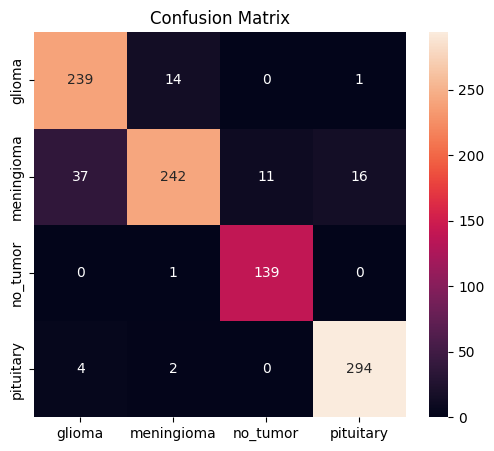


✅ Segmentation
   Dice : 0.8595
   IoU  : 0.7536


              precision    recall  f1-score   support

  Background       1.00      1.00      1.00  18557063
       Tumor       0.90      0.82      0.86    317305

    accuracy                           1.00  18874368
   macro avg       0.95      0.91      0.93  18874368
weighted avg       1.00      1.00      1.00  18874368



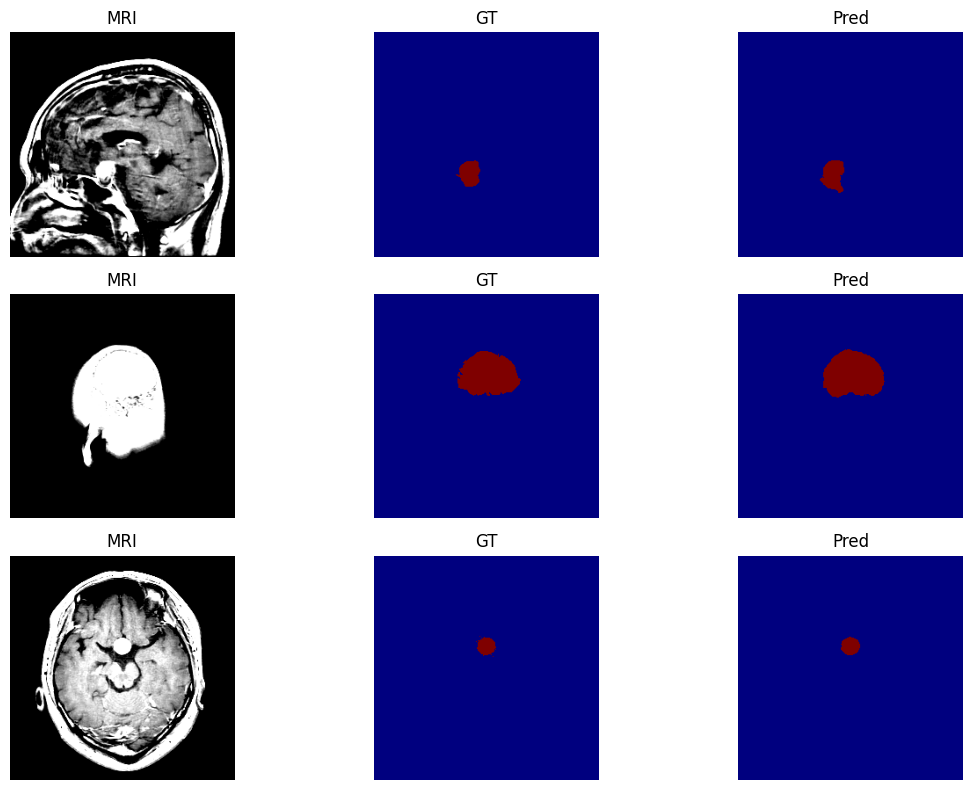

In [ ]:
# ── Classification Evaluation ────────────────────────────────
preds = np.argmax(clf_model.predict(test_gen), axis=1)
true  = test_gen.classes
labels = list(train_gen.class_indices.keys())

print(classification_report(true, preds, target_names=labels))

cm = confusion_matrix(true, preds)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix'); plt.show()

# ── Segmentation Evaluation ──────────────────────────────────
test_data = DataGenerator(list(X_test.filepath), list(X_test.mask_path), shuffle=False)

all_true, all_pred = [], []
for i in range(len(test_data)):
    xb, yb = test_data[i]
    pb = (seg_model.predict(xb, verbose=0) > 0.5).astype(int)
    all_true.append(yb); all_pred.append(pb)

all_true = np.concatenate(all_true).flatten()
all_pred = np.concatenate(all_pred).flatten()

inter = np.sum(all_true * all_pred)
dice  = (2.*inter + 1e-6) / (np.sum(all_true) + np.sum(all_pred) + 1e-6)
iou   = (inter + 1e-6) / (np.sum(all_true) + np.sum(all_pred) - inter + 1e-6)

print(f"\n✅ Segmentation")
print(f"   Dice : {dice:.4f}")
print(f"   IoU  : {iou:.4f}")
print(classification_report(all_true.astype(int), all_pred.astype(int),
      target_names=['Background','Tumor']))

# ── Visual check ─────────────────────────────────────────────
xv, yv = test_data[0]
pv = (seg_model.predict(xv, verbose=0) > 0.5).astype(int)
plt.figure(figsize=(12,8))
for i in range(3):
    plt.subplot(3,3,i*3+1); plt.imshow(xv[i]); plt.title('MRI'); plt.axis('off')
    plt.subplot(3,3,i*3+2); plt.imshow(yv[i].squeeze(),cmap='jet'); plt.title('GT'); plt.axis('off')
    plt.subplot(3,3,i*3+3); plt.imshow(pv[i].squeeze(),cmap='jet'); plt.title('Pred'); plt.axis('off')
plt.tight_layout(); plt.show()

Saving brain1.jpg to brain1.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 19s 19s/step
Prediction : meningioma
Confidence : 42.33%
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
Tumor Area : 2.82%


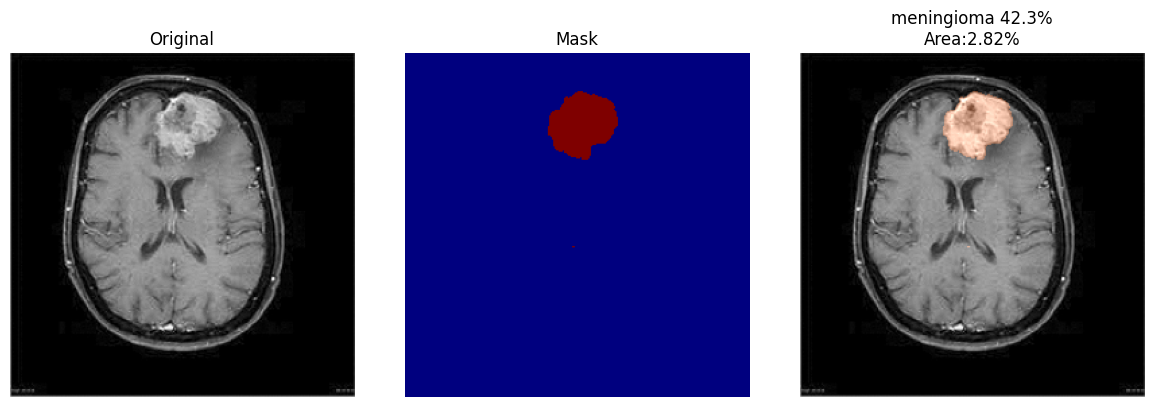

In [ ]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()
img_path = list(uploaded.keys())[0]

# ── Preprocess ───────────────────────────────────────────────
img_bgr = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# Classification
img_clf = cv2.resize(img_rgb, (256, 256)) / 255.0
img_clf = np.expand_dims(img_clf, axis=0)
preds   = clf_model.predict(img_clf)
labels  = list(train_gen.class_indices.keys())
pred_label = labels[np.argmax(preds[0])]
confidence = float(np.max(preds[0])) * 100
print(f"Prediction : {pred_label}")
print(f"Confidence : {confidence:.2f}%")

# Segmentation
img_seg = cv2.resize(img_rgb, (256, 256)).astype(np.float64)
img_seg = (img_seg - img_seg.mean()) / (img_seg.std() + 1e-8)
img_seg = np.expand_dims(img_seg, axis=0)
mask    = seg_model.predict(img_seg)[0, :, :, 0]
mask_bin = (mask > 0.3).astype(np.uint8)
area_pct = round(np.sum(mask_bin) / (256*256) * 100, 2)
print(f"Tumor Area : {area_pct}%")

# ── Visualize ────────────────────────────────────────────────
overlay = img_rgb.copy()
overlay_resized = cv2.resize(overlay, (256, 256))
colored_mask = np.zeros_like(overlay_resized)
colored_mask[:,:,0] = mask_bin * 180  # blue
colored_mask[:,:,1] = mask_bin * 60

result = cv2.addWeighted(overlay_resized, 1.0, colored_mask, 0.4, 0)

plt.figure(figsize=(12,4))
plt.subplot(1,3,1); plt.imshow(overlay_resized); plt.title('Original'); plt.axis('off')
plt.subplot(1,3,2); plt.imshow(mask_bin, cmap='jet'); plt.title('Mask'); plt.axis('off')
plt.subplot(1,3,3); plt.imshow(result); plt.title(f'{pred_label} {confidence:.1f}%\nArea:{area_pct}%'); plt.axis('off')
plt.tight_layout(); plt.show()

Saving pt2.jpg to pt2 (2).jpg


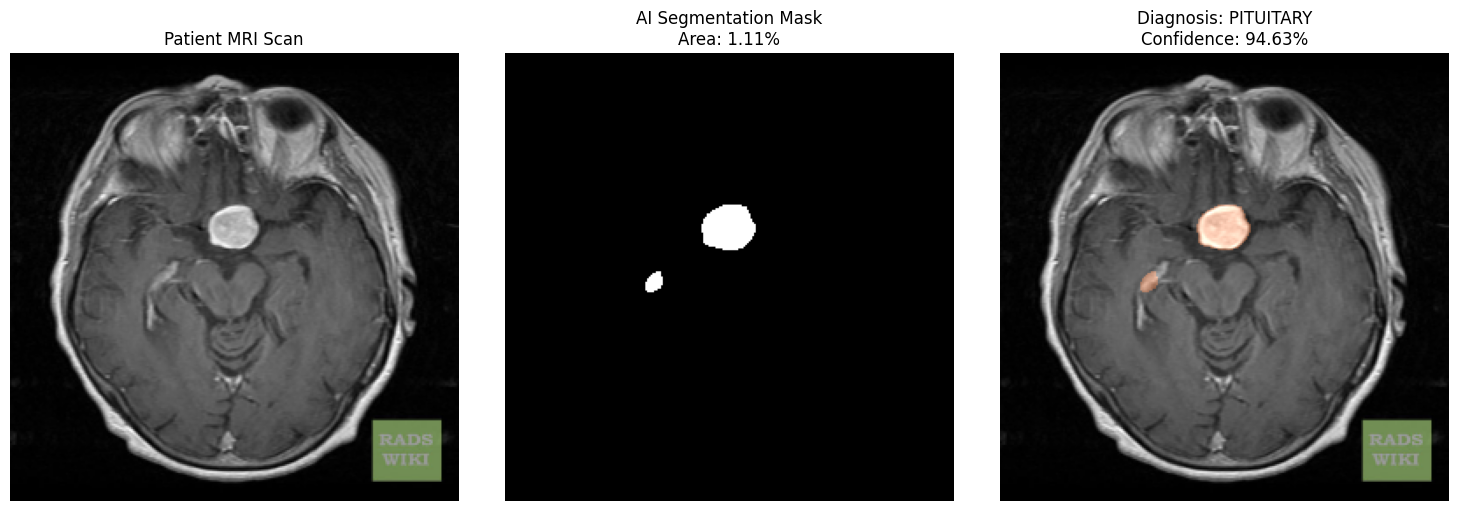


[SUMMARY] Detected: pituitary | Confidence: 94.63% | Tumor Area: 1.11%


In [ ]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Upload File
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

# 2. Load and Prepare Original Image (for display)
img_bgr = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
display_img = cv2.resize(img_rgb, (256, 256))

# ─── STEP 1: CLASSIFICATION ──────────────────────────────────────────
# Preprocess for VGG16/CNN (Rescaling 0-1)
img_clf = cv2.resize(img_rgb, (256, 256)) / 255.0
img_clf = np.expand_dims(img_clf, axis=0)

preds = clf_model.predict(img_clf, verbose=0)
labels = list(train_gen.class_indices.keys())
pred_idx = np.argmax(preds[0])
pred_label = labels[pred_idx]
confidence = float(preds[0][pred_idx]) * 100

# ─── STEP 2: SEGMENTATION ────────────────────────────────────────────
# Preprocess for ResUNet (Standardization)
img_seg = cv2.resize(img_rgb, (256, 256)).astype(np.float64)
img_seg = (img_seg - img_seg.mean()) / (img_seg.std() + 1e-8)
img_seg = np.expand_dims(img_seg, axis=0)

mask_output = seg_model.predict(img_seg, verbose=0)[0, :, :, 0]
mask_bin = (mask_output > 0.5).astype(np.uint8)
area_pct = round(np.sum(mask_bin) / (256*256) * 100, 2)

# ─── STEP 3: GATEKEEPER LOGIC (The Fix) ──────────────────────────────
# If classification says "no_tumor", or area is negligible noise (<0.2%)
# we force the output to be clean.
if pred_label == "no_tumor" or area_pct < 0.2:
    mask_bin = np.zeros((256, 256), dtype=np.uint8)
    area_pct = 0.0
    # If the segmentor found nothing but classifier was unsure, trust segmentor
    if area_pct == 0.0 and pred_label != "no_tumor":
        pred_label = "no_tumor"
        confidence = preds[0][labels.index("no_tumor")] * 100

# ─── STEP 4: VISUALIZE ───────────────────────────────────────────────
overlay = display_img.copy()
colored_mask = np.zeros_like(display_img)

if np.any(mask_bin):
    colored_mask[:, :, 0] = mask_bin * 180  # Blue channel highlight
    colored_mask[:, :, 1] = mask_bin * 60   # Slight green tint for teal look

# Apply mask overlay only if tumor is confirmed
result = cv2.addWeighted(overlay, 1.0, colored_mask, 0.4, 0)

# Plotting
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(display_img)
plt.title('Patient MRI Scan')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(mask_bin, cmap='gray')
plt.title(f'AI Segmentation Mask\nArea: {area_pct}%')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(result)
plt.title(f'Diagnosis: {pred_label.upper()}\nConfidence: {confidence:.2f}%')
plt.axis('off')

plt.tight_layout()
plt.show()

print(f"\n[SUMMARY] Detected: {pred_label} | Confidence: {confidence:.2f}% | Tumor Area: {area_pct}%")

Saving no.jpg to no (1).jpg


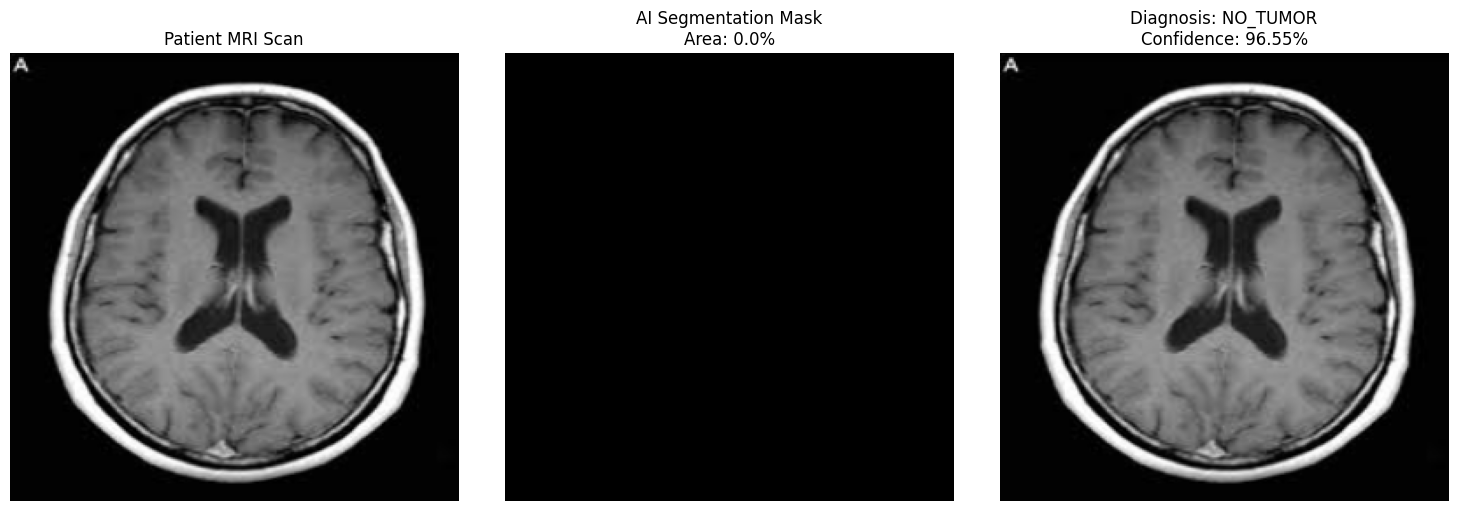


[SUMMARY] Detected: no_tumor | Confidence: 96.55% | Tumor Area: 0.0%


In [ ]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Upload File
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

# 2. Load and Prepare Original Image (for display)
img_bgr = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
display_img = cv2.resize(img_rgb, (256, 256))

# ─── STEP 1: CLASSIFICATION ──────────────────────────────────────────
# Preprocess for VGG16/CNN (Rescaling 0-1)
img_clf = cv2.resize(img_rgb, (256, 256)) / 255.0
img_clf = np.expand_dims(img_clf, axis=0)

preds = clf_model.predict(img_clf, verbose=0)
labels = list(train_gen.class_indices.keys())
pred_idx = np.argmax(preds[0])
pred_label = labels[pred_idx]
confidence = float(preds[0][pred_idx]) * 100

# ─── STEP 2: SEGMENTATION ────────────────────────────────────────────
# Preprocess for ResUNet (Standardization)
img_seg = cv2.resize(img_rgb, (256, 256)).astype(np.float64)
img_seg = (img_seg - img_seg.mean()) / (img_seg.std() + 1e-8)
img_seg = np.expand_dims(img_seg, axis=0)

mask_output = seg_model.predict(img_seg, verbose=0)[0, :, :, 0]
mask_bin = (mask_output > 0.5).astype(np.uint8)
area_pct = round(np.sum(mask_bin) / (256*256) * 100, 2)

# ─── STEP 3: GATEKEEPER LOGIC (The Fix) ──────────────────────────────
# If classification says "no_tumor", or area is negligible noise (<0.2%)
# we force the output to be clean.
if pred_label == "no_tumor" or area_pct < 0.2:
    mask_bin = np.zeros((256, 256), dtype=np.uint8)
    area_pct = 0.0
    # If the segmentor found nothing but classifier was unsure, trust segmentor
    if area_pct == 0.0 and pred_label != "no_tumor":
        pred_label = "no_tumor"
        confidence = preds[0][labels.index("no_tumor")] * 100

# ─── STEP 4: VISUALIZE ───────────────────────────────────────────────
overlay = display_img.copy()
colored_mask = np.zeros_like(display_img)

if np.any(mask_bin):
    colored_mask[:, :, 0] = mask_bin * 180  # Blue channel highlight
    colored_mask[:, :, 1] = mask_bin * 60   # Slight green tint for teal look

# Apply mask overlay only if tumor is confirmed
result = cv2.addWeighted(overlay, 1.0, colored_mask, 0.4, 0)

# Plotting
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(display_img)
plt.title('Patient MRI Scan')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(mask_bin, cmap='gray')
plt.title(f'AI Segmentation Mask\nArea: {area_pct}%')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(result)
plt.title(f'Diagnosis: {pred_label.upper()}\nConfidence: {confidence:.2f}%')
plt.axis('off')

plt.tight_layout()
plt.show()

print(f"\n[SUMMARY] Detected: {pred_label} | Confidence: {confidence:.2f}% | Tumor Area: {area_pct}%")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
label
pituitary     1757
meningioma    1635
glioma        1401
no_tumor      1207
Name: count, dtype: int64
Found 4500 validated image filenames belonging to 4 classes.
Found 500 validated image filenames belonging to 4 classes.
Found 1000 validated image filenames belonging to 4 classes.
Epoch 1/50
281/281 ━━━━━━━━━━━━━━━━━━━━ 0s 400ms/step - accuracy: 0.4643 - loss: 2.2252
Epoch 1: val_loss improved from None to 2.35370, saving model to resnet50_clf.keras

Epoch 1: finished saving model to resnet50_clf.keras
281/281 ━━━━━━━━━━━━━━━━━━━━ 149s 465ms/step - accuracy: 0.5401 - loss: 1.9354 - val_accuracy: 0.0000e+00 - val_loss: 2.3537 - learning_rate: 1.0000e-04
Epoch 2/50
  1/281 ━━━━━━━━━━━━━━━━━━━━ 30s 108ms/step - accuracy: 0.6250 - loss: 1.6398

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 2: val_loss improved from 2.35370 to 2.32906, saving model to resnet50_clf.keras

Epoch 2: finished saving model to resnet50_clf.keras
281/281 ━━━━━━━━━━━━━━━━━━━━ 12s 41ms/step - accuracy: 0.6250 - loss: 1.6398 - val_accuracy: 0.0000e+00 - val_loss: 2.3291 - learning_rate: 1.0000e-04
Epoch 3/50
281/281 ━━━━━━━━━━━━━━━━━━━━ 0s 328ms/step - accuracy: 0.6436 - loss: 1.5522
Epoch 3: val_loss improved from 2.32906 to 2.10542, saving model to resnet50_clf.keras

Epoch 3: finished saving model to resnet50_clf.keras
281/281 ━━━━━━━━━━━━━━━━━━━━ 104s 368ms/step - accuracy: 0.6566 - loss: 1.5230 - val_accuracy: 0.0605 - val_loss: 2.1054 - learning_rate: 1.0000e-04
Epoch 4/50
  1/281 ━━━━━━━━━━━━━━━━━━━━ 28s 102ms/step - accuracy: 0.2500 - loss: 2.3467
Epoch 4: val_loss improved from 2.10542 to 2.08611, saving model to resnet50_clf.keras

Epoch 4: finished saving model to resnet50_clf.keras
281/281 ━━━━━━━━━━━━━━━━━━━━ 12s 42ms/step - accuracy: 0.2500 - loss: 2.3467 - val_accuracy: 0.0565

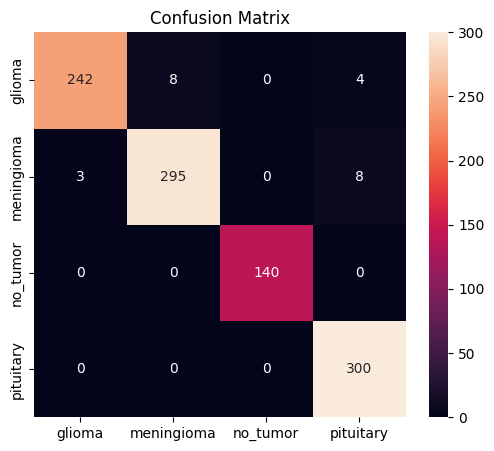

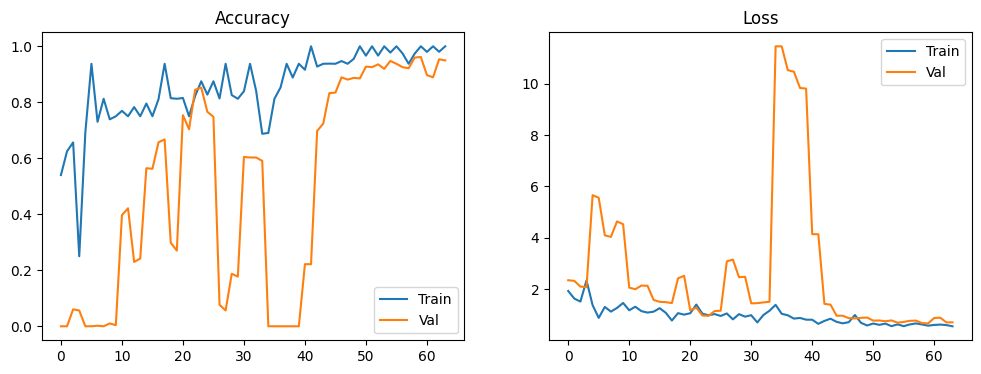

✅ Saved!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, cv2, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.regularizers import l2
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
IMG_SIZE = 256
BATCH_SIZE = 16

os.makedirs(os.path.expanduser('~/.kaggle'), exist_ok=True)
os.system('cp /content/drive/MyDrive/kaggle.json ~/.kaggle/')
os.system('chmod 600 ~/.kaggle/kaggle.json')

if not os.path.exists('./brisc_data'):
    os.system('pip install -q kaggle')
    os.system('kaggle datasets download -d briscdataset/brisc2025')
    os.system('unzip -q brisc2025.zip -d ./brisc_data')

BASE = './brisc_data/brisc2025'
clf_data = []
for split in ['train', 'test']:
    for label in ['glioma', 'meningioma', 'pituitary', 'no_tumor']:
        folder = f"{BASE}/classification_task/{split}/{label}"
        for fname in os.listdir(folder):
            clf_data.append({'filepath': f"{folder}/{fname}", 'label': label, 'split': split})

clf_df   = pd.DataFrame(clf_data)
train_df = clf_df[clf_df['split'] == 'train'].reset_index(drop=True)
test_df  = clf_df[clf_df['split'] == 'test'].reset_index(drop=True)
print(clf_df['label'].value_counts())

datagen = ImageDataGenerator(rescale=1./255., validation_split=0.1,
    rotation_range=15, zoom_range=0.1,
    horizontal_flip=True, brightness_range=[0.8, 1.2])

train_gen = datagen.flow_from_dataframe(train_df, x_col='filepath', y_col='label',
    subset='training', class_mode='categorical',
    batch_size=BATCH_SIZE, target_size=(IMG_SIZE, IMG_SIZE))

val_gen = datagen.flow_from_dataframe(train_df, x_col='filepath', y_col='label',
    subset='validation', class_mode='categorical',
    batch_size=BATCH_SIZE, target_size=(IMG_SIZE, IMG_SIZE))

test_gen = ImageDataGenerator(rescale=1./255.).flow_from_dataframe(
    test_df, x_col='filepath', y_col='label',
    class_mode='categorical', batch_size=BATCH_SIZE,
    shuffle=False, target_size=(IMG_SIZE, IMG_SIZE))

base = ResNet50(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
for layer in base.layers[:-20]: layer.trainable = False
for layer in base.layers[-20:]: layer.trainable = True

x   = base.output
x   = GlobalAveragePooling2D()(x)
x   = BatchNormalization()(x)
x   = Dense(256, activation='relu', kernel_regularizer=l2(0.001))(x)
x   = Dropout(0.5)(x)
x   = Dense(128, activation='relu', kernel_regularizer=l2(0.001))(x)
x   = Dropout(0.4)(x)
out = Dense(4, activation='softmax')(x)

clf_model = Model(base.input, out)
clf_model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
                  loss='categorical_crossentropy', metrics=['accuracy'])

history1 = clf_model.fit(train_gen,
    steps_per_epoch=train_gen.n // BATCH_SIZE,
    epochs=50, validation_data=val_gen,
    validation_steps=val_gen.n // BATCH_SIZE,
    callbacks=[
        ModelCheckpoint('resnet50_clf.keras', save_best_only=True, verbose=1),
        EarlyStopping(monitor='val_loss', patience=10, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', patience=5, factor=0.2, verbose=1)
    ])

for layer in base.layers:
    layer.trainable = True

clf_model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
                  loss='categorical_crossentropy', metrics=['accuracy'])

history2 = clf_model.fit(train_gen,
    steps_per_epoch=train_gen.n // BATCH_SIZE,
    epochs=30, validation_data=val_gen,
    validation_steps=val_gen.n // BATCH_SIZE,
    callbacks=[
        ModelCheckpoint('resnet50_clf_v2.keras', save_best_only=True, verbose=1),
        EarlyStopping(monitor='val_loss', patience=8, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', patience=4, factor=0.5, verbose=1)
    ])

train_loss, train_acc = clf_model.evaluate(train_gen, verbose=0)
val_loss,   val_acc   = clf_model.evaluate(val_gen,   verbose=0)
test_loss,  test_acc  = clf_model.evaluate(test_gen,  verbose=0)
print(f"Train : {train_acc*100:.2f}%")
print(f"Val   : {val_acc*100:.2f}%")
print(f"Test  : {test_acc*100:.2f}%")

preds = np.argmax(clf_model.predict(test_gen), axis=1)
labels = list(train_gen.class_indices.keys())
print(classification_report(test_gen.classes, preds, target_names=labels))

cm = confusion_matrix(test_gen.classes, preds)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix'); plt.show()

# Plot training curves
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history1.history['accuracy'] + history2.history['accuracy'], label='Train')
plt.plot(history1.history['val_accuracy'] + history2.history['val_accuracy'], label='Val')
plt.title('Accuracy'); plt.legend()
plt.subplot(1,2,2)
plt.plot(history1.history['loss'] + history2.history['loss'], label='Train')
plt.plot(history1.history['val_loss'] + history2.history['val_loss'], label='Val')
plt.title('Loss'); plt.legend()
plt.show()

clf_model.save('/content/drive/MyDrive/resnet50_clf_brisc.keras')
print("✅ Saved!")

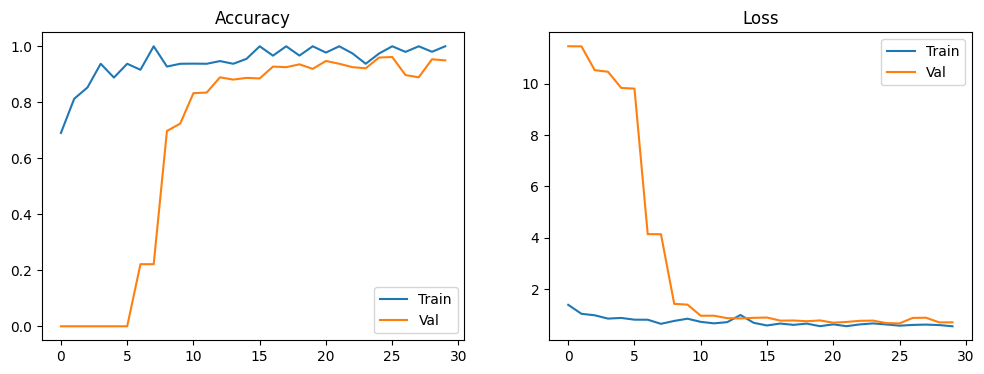

In [ ]:
# Plot Phase 2 only
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history2.history['accuracy'], label='Train')
plt.plot(history2.history['val_accuracy'], label='Val')
plt.title('Accuracy'); plt.legend()
plt.subplot(1,2,2)
plt.plot(history2.history['loss'], label='Train')
plt.plot(history2.history['val_loss'], label='Val')
plt.title('Loss'); plt.legend()
plt.show()

In [8]:
clf_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 262, 262,  │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 128, 128,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 128, 128,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 128, 128,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 130, 130,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 64, 64,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 64, 64,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 64, 64,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 64, 64,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 64, 64,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 64, 64,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 64, 64,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 64, 64,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 64, 64,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 64, 64,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 64, 64,    │      1,024 │ conv2_block1_3_c

 Total params: 72,347,150 (275.98 MB)

 Trainable params: 24,096,644 (91.92 MB)

 Non-trainable params: 57,216 (223.50 KB)

 Optimizer params: 48,193,290 (183.84 MB)